# Assignment 1: Data Profiling (EDA) Report
**Team Members:** 
- Muhammad Ayli Haziq bin Sazali (A210683)
- [Member 2 Name] (Matric No: [Insert])
- [Member 3 Name] (Matric No: [Insert])
- [Member 4 Name] (Matric No: [Insert])

## **1. Scenario** 

Our university department is seeking to eliminate passive learning in traditional classroom environments by integrating interactive AI and multimedia tools. We are analyzing the Open University's Virtual Learning Environment (VLE) interaction logs alongside demographic data to identify passivity patterns. By diagnosing this messy data, we aim to uncover which student segments show total disengagement (zero clicks) or abnormal behavior, indicating a need for AI interventions.


## **2. Data Source**

Source: Kaggle (Open University Learning Analytics Dataset - OULAD)

URL: [https://www.kaggle.com/datasets/rocki37/open-university-learning-analytics-dataset]
    
How it was obtained: Downloaded via Kaggle API. We are combining `studentInfo.csv` (demographics) with an aggregated version of `studentVle.csv` (daily click interactions) to profile engagement.

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import hashlib

info_df = pd.read_csv('studentInfo.csv')
vle_df = pd.read_csv('studentVle.csv')

vle_agg = vle_df.groupby('id_student')['sum_click'].sum().reset_index()

vle_agg = vle_agg.rename(columns={'sum_click': 'total_clicks'})

df = pd.merge(info_df, vle_agg, on='id_student', how='left')

display(df.head())
display(df.info())

,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result,total_clicks
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass,934.0
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass,1435.0
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,Withdrawn,281.0
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass,2158.0
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass,1034.0


<class 'pandas.DataFrame'>
RangeIndex: 32593 entries, 0 to 32592
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   code_module           32593 non-null  str    
 1   code_presentation     32593 non-null  str    
 2   id_student            32593 non-null  int64  
 3   gender                32593 non-null  str    
 4   region                32593 non-null  str    
 5   highest_education     32593 non-null  str    
 6   imd_band              31482 non-null  str    
 7   age_band              32593 non-null  str    
 8   num_of_prev_attempts  32593 non-null  int64  
 9   studied_credits       32593 non-null  int64  
 10  disability            32593 non-null  str    
 11  final_result          32593 non-null  str    
 12  total_clicks          29741 non-null  float64
dtypes: float64(1), int64(3), str(9)
memory usage: 3.2 MB


None

## **3. Data Profiling and Issue Handling**

### A. Missing Values
**Diagnosis:** Because we performed a left join, students who never interacted with the online environment have `NaN` in `total_clicks`. Additionally, the `imd_band` (Index of Multiple Deprivation) column contains missing values disguised as `"?"` strings.

**Action & Justification:**
*   `total_clicks`: Imputed with `0`. Dropping these rows would eliminate our most critical target demographic: completely passive students.
*   `imd_band`: Converted `"?"` to actual `NaN` values, then imputed with the mode (most frequent category) to preserve the row data for other demographic analyses.

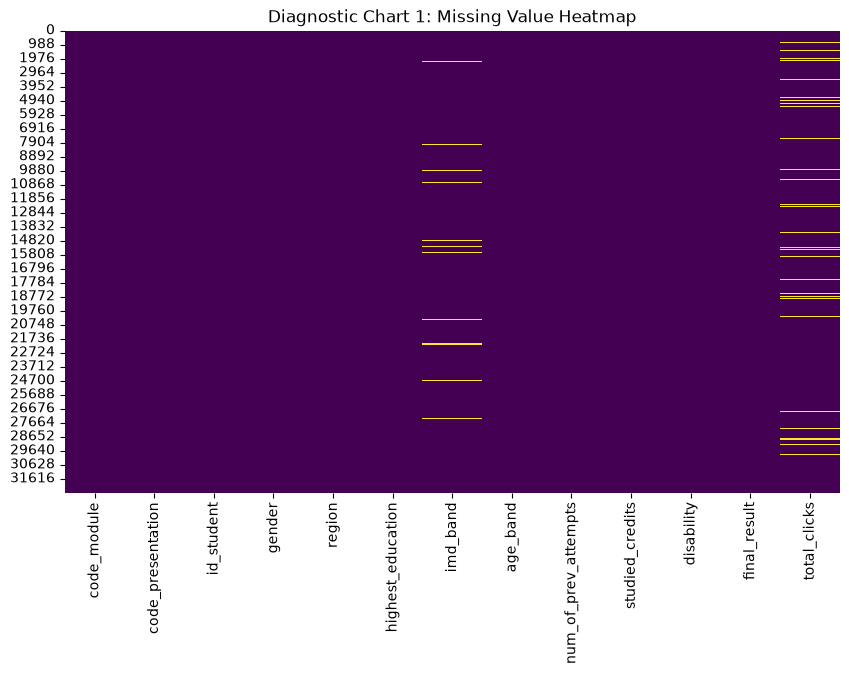

Missing values after imputation:
 code_module             0
code_presentation       0
id_student              0
gender                  0
region                  0
highest_education       0
imd_band                0
age_band                0
num_of_prev_attempts    0
studied_credits         0
disability              0
final_result            0
total_clicks            0
dtype: int64


In [9]:
df['imd_band'] = df['imd_band'].replace('?', np.nan)

plt.figure(figsize=(10, 6))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
plt.title('Diagnostic Chart 1: Missing Value Heatmap')
plt.show()

df['total_clicks'] = df['total_clicks'].fillna(0)

mode_imd = df['imd_band'].mode()[0]
df['imd_band'] = df['imd_band'].fillna(mode_imd)

print("Missing values after imputation:\n", df.isnull().sum())

### **B. Outliers**
**Diagnosis:** Used a boxplot to evaluate `total_clicks`. We found extreme outliers where a few students logged hundreds of thousands of clicks, likely due to system errors, bot scripts, or leaving a refreshing tab open.

**Action & Justification:** 
Capped the extreme outliers at the 95th percentile using the Interquartile Range (IQR) method. We did not delete them because the students' demographic data and final results remain valid for our evaluation.

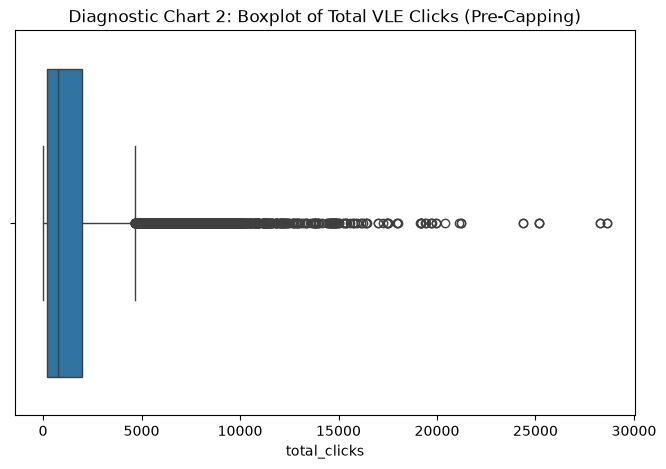

In [10]:
plt.figure(figsize=(8, 5))
sns.boxplot(x=df['total_clicks'])
plt.title('Diagnostic Chart 2: Boxplot of Total VLE Clicks (Pre-Capping)')
plt.show()

Q1 = df['total_clicks'].quantile(0.25)
Q3 = df['total_clicks'].quantile(0.75)
IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR

df['total_clicks'] = np.where(
    df['total_clicks'] > upper_bound, 
    upper_bound, 
    df['total_clicks']
)

### **C. Other Quality Issues**
**Diagnosis:** 
1.  **Duplicates:** Log merges can sometimes result in duplicated student profiles.
2.  **Inconsistent Formats:** The `highest_education` column contains overly long, messy string categories that make analysis cumbersome.

**Action & Justification:**
*   Dropped exact duplicate rows based on `id_student` to prevent double-counting demographics.
*   Standardized and simplified the education strings to create cleaner categorical groupings.

Dropped 0 duplicate rows.


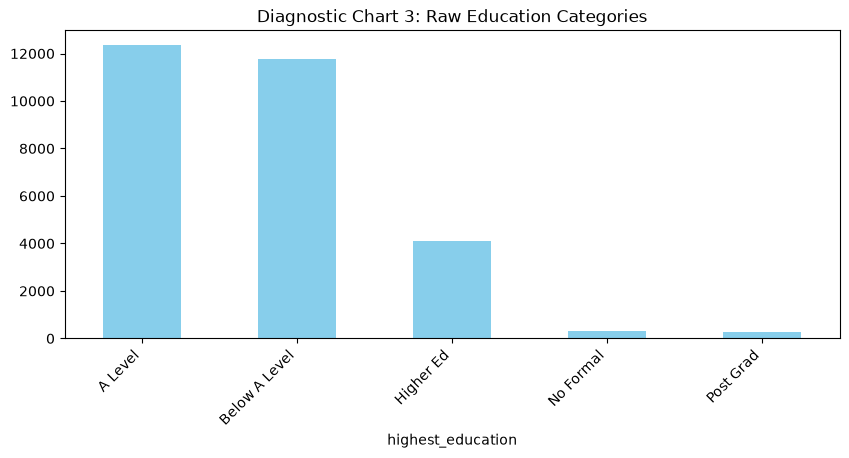

Cleaned Education Categories: <StringArray>
['Higher Ed', 'A Level', 'Below A Level', 'Post Grad', 'No Formal']
Length: 5, dtype: str


In [12]:
duplicates_count = df.duplicated(subset=['id_student']).sum()
df = df.drop_duplicates(subset=['id_student'])
print(f"Dropped {duplicates_count} duplicate rows.")

plt.figure(figsize=(10, 4))
df['highest_education'].value_counts().plot(kind='bar', color='skyblue')
plt.title('Diagnostic Chart 3: Raw Education Categories')
plt.xticks(rotation=45, ha='right')
plt.show()

education_mapping = {
    'A Level or Equivalent': 'A Level',
    'Lower Than A Level': 'Below A Level',
    'HE Qualification': 'Higher Ed',
    'Post Graduate Qualification': 'Post Grad',
    'No Formal quals': 'No Formal'
}
df['highest_education'] = df['highest_education'].replace(education_mapping)
print("Cleaned Education Categories:", df['highest_education'].unique())

## **4. Exploratory (Diagnostic) Charts**

## **5. PII and Bias Risks**

## **6. Conclusion**